# 12.1 문제 정의
데이터들을 비슷한 속성끼리 분류하라.

여기에서는 2개의 데이터를 사용합니다. 첫번째 데이터는 K-평균 군집화를 학습할 목적으로 인위적으로 만든 데이터로, 변수들에는 아무런 의미가 없습니다. 두번째 데이터는 11장에서 사용한 데이터 중 일부 변수와 일부 고객 정보만을 포함합니다.

## 12.2 K-평균 군집화 맛보기 : 인위적으로 만든 데이터셋


### 12.2.1 라이브러리 및 연습용 데이터 불러오기, 데이터 확인하기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_url = 'https://raw.githubusercontent.com/snkn1959/data_source/main/example_cluster.csv'
data = pd.read_csv(file_url)

In [2]:
data

,var_1,var_2
0,3.264413,6.929164
1,0.220814,2.251631
2,-8.786197,-8.333582
3,-0.008547,2.630791
4,4.912903,6.888520
...,...,...
995,4.678232,7.704404
996,5.250715,6.930948
997,-11.818752,-5.609853
998,0.613725,3.809334


<Axes: xlabel='var_1', ylabel='var_2'>

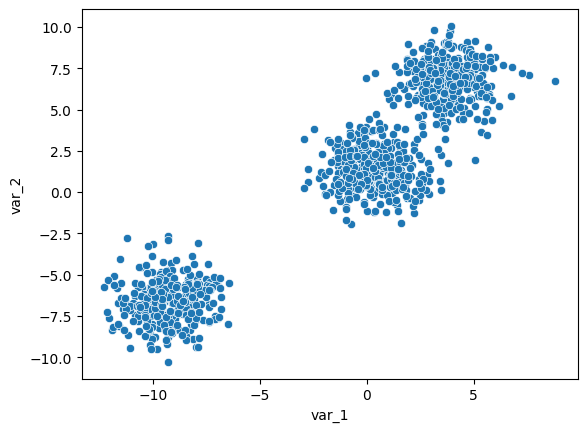

In [3]:
# 산점도 그리기
sns.scatterplot(x='var_1', y = 'var_2', data= data)

### 12.2.2 연습용 데이터 모델링 및 평가

In [4]:
from sklearn.cluster import KMeans

In [5]:
# 모델 객체 생성
kmeans_model = KMeans(n_clusters=3, random_state = 100)

In [6]:
# 학습
kmeans_model.fit(data)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,100
,copy_x,True
,algorithm,'lloyd'


In [7]:
# 예측
kmeans_model.predict(data)

array([2, 1, 0, 1, 2, 1, 2, 0, 2, 2, 2, 2, 1, 2, 0, 1, 0, 2, 2, 0, 1, 0,
       0, 0, 1, 2, 1, 0, 1, 1, 1, 0, 1, 2, 2, 0, 0, 2, 2, 2, 1, 1, 2, 1,
       0, 2, 2, 1, 0, 1, 2, 0, 2, 1, 2, 0, 0, 0, 1, 1, 1, 2, 1, 2, 0, 2,
       1, 0, 2, 0, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 0, 1, 2, 2, 1, 2,
       0, 1, 2, 1, 0, 1, 0, 0, 0, 2, 1, 1, 1, 0, 0, 1, 0, 2, 0, 0, 0, 2,
       0, 1, 2, 1, 1, 1, 0, 1, 0, 0, 2, 2, 1, 0, 1, 0, 1, 0, 2, 2, 0, 2,
       1, 2, 0, 2, 1, 1, 1, 2, 1, 2, 0, 0, 1, 2, 0, 1, 1, 2, 2, 1, 1, 2,
       2, 2, 1, 0, 2, 0, 2, 1, 2, 0, 0, 2, 1, 2, 0, 2, 1, 2, 0, 2, 2, 0,
       1, 2, 0, 1, 1, 0, 1, 1, 2, 2, 2, 1, 2, 0, 1, 1, 1, 0, 2, 1, 1, 1,
       2, 2, 2, 1, 1, 1, 2, 0, 1, 1, 1, 0, 0, 2, 1, 2, 1, 0, 0, 2, 1, 0,
       1, 1, 0, 2, 0, 0, 2, 0, 2, 1, 0, 2, 2, 0, 0, 0, 2, 2, 2, 0, 1, 0,
       2, 0, 0, 2, 1, 0, 2, 2, 0, 2, 1, 0, 2, 1, 0, 0, 1, 0, 2, 0, 2, 1,
       1, 1, 0, 2, 1, 2, 2, 2, 2, 0, 2, 0, 1, 1, 2, 0, 1, 0, 2, 0, 1, 1,
       1, 1, 1, 0, 1, 2, 1, 2, 1, 2, 0, 1, 0, 1, 1,

In [8]:
# 예측값을 label로 저장
data['label'] = kmeans_model.predict(data)

<Axes: xlabel='var_1', ylabel='var_2'>

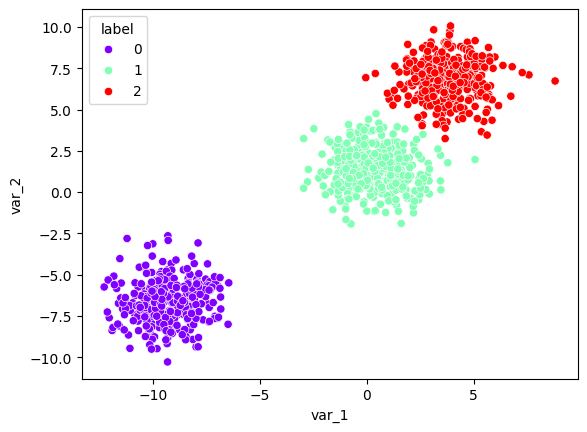

In [9]:
# 산점도 그리기
sns.scatterplot(x='var_1', y = 'var_2', data= data, hue='label', palette='rainbow')

### 12.2.3 엘보우 기법으로 최적의 K값 구하기
- 엘보우 기법(elbow method)  
  : 최적의 클러스터 개수를 확인하는 방법으로, 클러스터의 중점과 각 데이터 간의 거리를 기반으로 계산합니다.(distance가 급격히 줄어드는 K값을 포착하여 최적의 K값을 찾도록 도와주는 방법론)

- 이너셔(inertia)  
  : 각 그룹에서의 중심과 각 그룹에 해당하는 데이터 간의 거리에 대한 합

In [10]:
# 이니셔 확인
kmeans_model.inertia_

3090.0332370766614

In [11]:
temp_model = KMeans(n_clusters=500, random_state = 100)
temp_model.fit(data)
temp_model.inertia_

6.341205909239226

In [12]:
distance = []   # ❶ 빈 리스트 생성
for k in range(2,10):
    k_model = KMeans(n_clusters=k)
    k_model.fit(data)    
    distance.append(k_model.inertia_) # ❷ 이니셔를 리스트에 저장

In [13]:
distance  # 저장된 이니셔 확인

[9908.551424778394,
 3090.033237076662,
 2717.1810299269496,
 2381.639739360635,
 2190.494588067064,
 1860.9632134895128,
 1599.9715382817756,
 1387.0025547940177]

<Axes: >

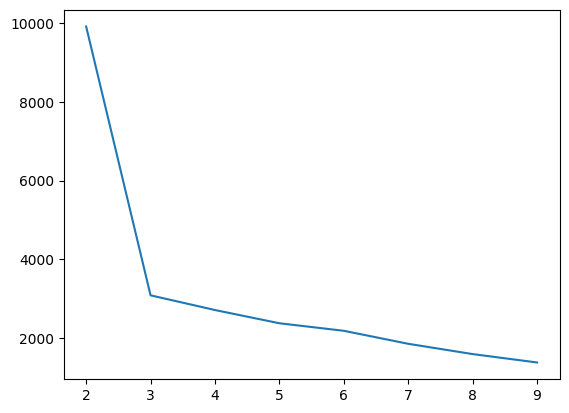

In [14]:
# 엘보우 플랏 그리기
sns.lineplot(x=range(2,10), y=distance)

## 12.3 데이터 불러오기 및 데이터 확인하기 : 고객 데이터셋


In [15]:
file_url = 'https://raw.githubusercontent.com/snkn1959/data_source/main/customer.csv'
customer = pd.read_csv(file_url)

In [16]:
customer.head()

,cc_num,category,amt
0,2703186189652095,misc,4.97
1,630423337322,grocery,107.23
2,38859492057661,entertainment,220.11
3,3534093764340240,gas_transport,45.00
4,375534208663984,misc,41.96


In [17]:
customer.shape

(240454, 3)

In [18]:
# 카드번호의 고윳값 확인
customer['cc_num'].nunique()

100

In [19]:
# 카테고리의 고윳값 확인
customer['category'].nunique()

11

In [20]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240454 entries, 0 to 240453
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   cc_num    240454 non-null  int64  
 1   category  240454 non-null  object 
 2   amt       240454 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 5.5+ MB


## 12.4 전처리 : 피처 엔지니어링


In [21]:
# 카테고리를 더미 변수로 변환
customer_dummy = pd.get_dummies(customer, columns =['category'])

In [22]:
customer_dummy.head()

,cc_num,amt,category_entertainment,category_food_dining,category_gas_transport,category_grocery,category_health_fitness,category_home,category_kids_pets,category_misc,category_personal_care,category_shopping,category_travel
0,2703186189652095,4.97,False,False,False,False,False,False,False,True,False,False,False
1,630423337322,107.23,False,False,False,True,False,False,False,False,False,False,False
2,38859492057661,220.11,True,False,False,False,False,False,False,False,False,False,False
3,3534093764340240,45.00,False,False,True,False,False,False,False,False,False,False,False
4,375534208663984,41.96,False,False,False,False,False,False,False,True,False,False,False


In [23]:
# 변수 이름 리스트 생성
cat_list = customer_dummy.columns[2:]

In [24]:
# 금액으로 변수 업데이트
for i in cat_list:
    customer_dummy[i] = customer_dummy[i] * customer_dummy['amt']

In [25]:
customer_dummy

,cc_num,amt,category_entertainment,category_food_dining,category_gas_transport,category_grocery,category_health_fitness,category_home,category_kids_pets,category_misc,category_personal_care,category_shopping,category_travel
0,2703186189652095,4.97,0.00,0.0,0.0,0.00,0.00,0.0,0.0,4.97,0.0,0.00,0.0
1,630423337322,107.23,0.00,0.0,0.0,107.23,0.00,0.0,0.0,0.00,0.0,0.00,0.0
2,38859492057661,220.11,220.11,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.0
3,3534093764340240,45.00,0.00,0.0,45.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.0
4,375534208663984,41.96,0.00,0.0,0.0,0.00,0.00,0.0,0.0,41.96,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
240449,4716561796955522,4.93,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,4.93,0.0
240450,30074693890476,140.12,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,140.12,0.0
240451,30404291151692,37.79,0.00,0.0,0.0,0.00,37.79,0.0,0.0,0.00,0.0,0.00,0.0
240452,4922710831011201,17.50,17.50,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.0


In [26]:
# cc_num별 총 금액
customer_agg = customer_dummy.groupby('cc_num').sum()

In [27]:
customer_agg.head()

,amt,category_entertainment,category_food_dining,category_gas_transport,category_grocery,category_health_fitness,category_home,category_kids_pets,category_misc,category_personal_care,category_shopping,category_travel
cc_num,,,,,,,,,,,,
60495593109,48149.62,3169.74,4043.46,5076.36,7576.58,1631.22,5458.58,4924.97,4889.57,3135.25,8106.36,137.53
571365235126,259784.87,13864.51,9055.51,36525.79,48812.73,13685.60,19342.79,17726.82,32542.61,16672.08,45994.60,5561.83
571465035400,270081.63,16162.98,15448.75,9081.62,41643.82,15244.03,28282.98,13737.95,15880.82,8771.27,59454.96,46372.45
630412733309,41959.52,3212.46,1543.16,5786.98,8416.70,3201.04,2474.68,3648.97,3109.83,2592.17,7586.79,386.74
630423337322,244612.73,12786.75,6905.07,36460.40,43854.26,12136.74,21106.87,16807.24,32400.76,15885.32,44287.02,1982.30


In [28]:
# 스케일링
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # ❶ 스케일러 객체 생성
scaled_df = pd.DataFrame(scaler.fit_transform(customer_agg), # ❷ 데이터 프레임 형태로 변환
            columns = customer_agg.columns, # ❸ 데이터프레임 컬럼 이름 정의
            index=customer_agg.index) # ❹ 데이터프레임 인덱스 이름 정의

In [29]:
scaled_df.head()

,amt,category_entertainment,category_food_dining,category_gas_transport,category_grocery,category_health_fitness,category_home,category_kids_pets,category_misc,category_personal_care,category_shopping,category_travel
cc_num,,,,,,,,,,,,
60495593109,-1.402327,-1.135617,-0.971069,-1.000180,-1.118217,-1.561756,-1.145051,-1.276913,-1.124693,-1.070260,-1.141424,-0.619930
571365235126,1.079407,0.414075,0.168880,2.090013,0.767268,1.040236,0.844969,1.127922,1.210503,1.807350,0.659967,-0.222587
571465035400,1.200151,0.747127,1.622968,-0.606627,0.439476,1.376630,2.126364,0.378610,-0.196523,0.127825,1.299938,2.766891
630412733309,-1.474915,-1.129427,-1.539741,-0.930355,-1.079803,-1.222903,-1.572733,-1.516610,-1.274986,-1.185705,-1.166127,-0.601675
630423337322,0.901491,0.257905,-0.320220,2.083588,0.540547,0.705908,1.097814,0.955178,1.198524,1.640103,0.578781,-0.484796


## 12.5 고객 데이터 모델링 및 실루엣 계수

<Axes: >

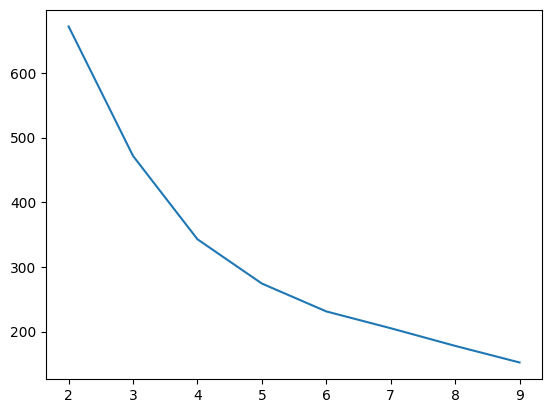

In [30]:
distance = []
for k in range(2,10):
    k_model = KMeans(n_clusters=k)  # 모델 객체 생성
    k_model.fit(scaled_df)  # 학습
    labels = k_model.predict(scaled_df)  # 예측
    distance.append(k_model.inertia_)  # 이너셔값 리스트에 추가

sns.lineplot(x=range(2,10), y=distance)  # 엘보우 플랏 그리기

- 실루엣 계수(silhouette coefficient)  
  : 엘보우 기법과 같이 최적의 클러스터 수를 찾는 방법으로, 엘보우 기법에서 적절한 클러스터 수를 찾지 못했을 때 대안으로 사용할 수 있습니다. 엘보우 기법보다 계산 시간이 오래 걸리는 단점이 있습니다.

In [31]:
from sklearn.metrics import silhouette_score

In [32]:
silhouette = []
for k in range(2,10):
    k_model = KMeans(n_clusters=k)
    k_model.fit(scaled_df)
    labels = k_model.predict(scaled_df)
    silhouette.append(silhouette_score(scaled_df, labels))  # 실루엣 계수 리스트에 추가

<Axes: >

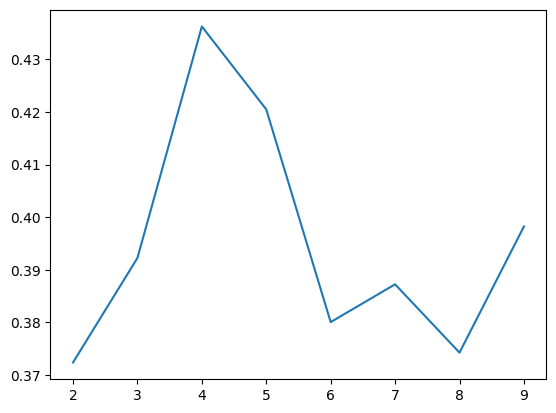

In [33]:
sns.lineplot(x=range(2,10), y=silhouette)  # 선형 그래프 그리기
# 실루엣 계수는 높은 값일 수록 더 좋은 분류를 의미

## 12.6 최종 예측 모델 및 결과 해석


In [34]:
k_model = KMeans(n_clusters=4)
k_model.fit(scaled_df)
labels = k_model.predict(scaled_df)

In [35]:
# label변수 정의
scaled_df['label'] = labels

In [36]:
scaled_df_mean = scaled_df.groupby('label').mean() # ❶ label별 평균값
scaled_df_count = scaled_df.groupby('label').count()['category_travel'] # ❷ label별 등장 횟수

In [37]:
scaled_df_count = scaled_df_count.rename('count')  # 이름 변경

In [38]:
scaled_df_all = scaled_df_mean.join(scaled_df_count)  # 데이터 합치기

In [39]:
scaled_df_all  # 완선된 데이터 출력

,amt,category_entertainment,category_food_dining,category_gas_transport,category_grocery,category_health_fitness,category_home,category_kids_pets,category_misc,category_personal_care,category_shopping,category_travel,count
label,,,,,,,,,,,,,
0,1.000533,0.776166,1.036432,-0.749213,0.310577,1.175961,1.794775,-0.011510,-0.311453,-0.093603,0.989477,3.050970,8
1,-0.983797,-0.826826,-0.820264,-0.807530,-0.746914,-1.037601,-0.943190,-1.017107,-0.788890,-0.903252,-0.760563,-0.266604,36
2,1.908120,2.155375,1.796299,-0.490418,2.290553,1.155923,0.943950,1.255997,2.005393,1.756210,2.272314,-0.262740,10
3,0.181113,0.043536,0.071197,0.868891,0.032581,0.356233,0.220808,0.524956,0.235603,0.341387,-0.070841,-0.264840,46
